# Simple and Multiple Linear Regression

This notebook creates a reproducible synthetic dataset, saves and reloads it as a CSV, and compares Simple Linear Regression (SLR) with Multiple Linear Regression (MLR). It uses a held-out test set to evaluate how well each model predicts a continuous target.

## 1. Import the required libraries

The notebook uses NumPy and pandas for data creation and handling, scikit-learn for splitting, modeling, and metrics, and Matplotlib for plots.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

## 2. Generate, save, and load the dataset

We create 5,000 observations with three numerical features. The target is based on a known linear combination of those features plus random noise. A fixed random seed makes the generated data reproducible. The CSV is saved next to this notebook, so no pre-existing data file is needed.

In [2]:
random_generator = np.random.default_rng(42)
n_observations = 5_000

tv_spend = random_generator.uniform(0, 100, n_observations)
radio_spend = random_generator.uniform(0, 50, n_observations)
social_media_spend = random_generator.uniform(0, 80, n_observations)
noise = random_generator.normal(0, 15, n_observations)

sales = (
    7
    + 3.2 * tv_spend
    + 5.1 * radio_spend
    + 1.8 * social_media_spend
    + noise
)

generated_data = pd.DataFrame(
    {
        "tv_spend": tv_spend,
        "radio_spend": radio_spend,
        "social_media_spend": social_media_spend,
        "sales": sales,
    }
)

csv_path = "regression_data.csv"
generated_data.to_csv(csv_path, index=False)

data = pd.read_csv(csv_path)
print(f"Dataset shape: {data.shape}")
data.head()

Dataset shape: (5000, 4)


,tv_spend,radio_spend,social_media_spend,sales
0,77.395605,10.907459,57.658271,435.505332
1,43.887844,33.146385,56.899021,445.369518
2,85.859792,38.343076,16.215602,511.446248
3,69.736803,8.331807,2.932432,259.515127
4,9.417735,2.192914,24.303962,118.655589


## 3. Choose features: SLR versus MLR

**Simple Linear Regression (SLR)** uses one input feature to predict a target. Here, SLR uses `tv_spend` only. **Multiple Linear Regression (MLR)** uses more than one input feature; here, it uses `tv_spend`, `radio_spend`, and `social_media_spend` together. Both models predict the same continuous `sales` target.

In [3]:
target = data["sales"]
slr_features = data[["tv_spend"]]
mlr_features = data[["tv_spend", "radio_spend", "social_media_spend"]]

(
    X_slr_train,
    X_slr_test,
    X_mlr_train,
    X_mlr_test,
    y_train,
    y_test,
) = train_test_split(
    slr_features,
    mlr_features,
    target,
    test_size=0.2,
    random_state=42,
)

print(f"Training observations: {len(y_train)}")
print(f"Testing observations: {len(y_test)}")

Training observations: 4000
Testing observations: 1000


## 4. Train both models and make test-set predictions

Each model is fitted using only the training data. The test data is kept separate until prediction and evaluation.

In [4]:
slr_model = LinearRegression()
slr_model.fit(X_slr_train, y_train)
slr_predictions = slr_model.predict(X_slr_test)

mlr_model = LinearRegression()
mlr_model.fit(X_mlr_train, y_train)
mlr_predictions = mlr_model.predict(X_mlr_test)

print(f"SLR coefficient for tv_spend: {slr_model.coef_[0]:.3f}")
print(f"MLR coefficients: {dict(zip(X_mlr_train.columns, mlr_model.coef_.round(3)))}")

SLR coefficient for tv_spend: 3.302
MLR coefficients: {'tv_spend': np.float64(3.208), 'radio_spend': np.float64(5.096), 'social_media_spend': np.float64(1.796)}


## 5. Evaluate the models

- **Mean Squared Error (MSE):** the average squared difference between actual and predicted values. Lower is better; squaring makes large errors count more heavily, and the units are squared.
- **Mean Absolute Error (MAE):** the average absolute difference between actual and predicted values. Lower is better, and the units match the target.
- **R² score:** the proportion of target variation explained by the model relative to predicting the test-set mean. A score closer to 1 indicates a better fit; 0 is similar to that baseline, and a negative score is worse than the baseline.

MSE and MAE are non-negative, and their useful scale depends on the target. Compare both sets of metrics on this same test split.

In [5]:
def display_metrics(model_name, actual, predicted):
    print(f"{model_name} — test-set metrics")
    print(f"  MSE:  {mean_squared_error(actual, predicted):.3f}")
    print(f"  MAE:  {mean_absolute_error(actual, predicted):.3f}")
    print(f"  R²:   {r2_score(actual, predicted):.4f}")


display_metrics("Simple Linear Regression (SLR)", y_test, slr_predictions)
print()
display_metrics("Multiple Linear Regression (MLR)", y_test, mlr_predictions)

Simple Linear Regression (SLR) — test-set metrics
  MSE:  7389.643
  MAE:  71.454
  R²:   0.5273

Multiple Linear Regression (MLR) — test-set metrics
  MSE:  240.389
  MAE:  12.479
  R²:   0.9846


## 6. Compare actual and predicted values for 10 test observations

Each marker pair shows an actual value and its prediction for one of the first 10 observations in the test set. A vertical connecting line shows that observation's residual, computed as `actual - predicted`.

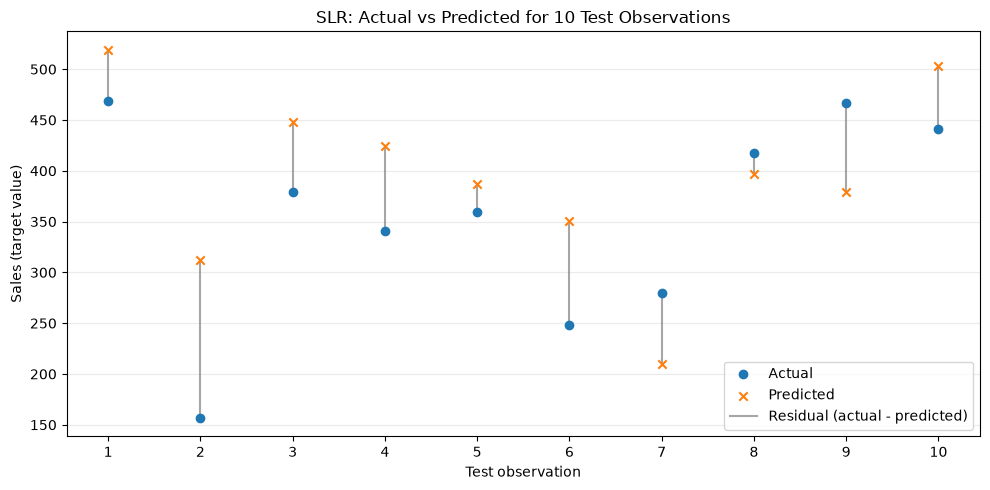

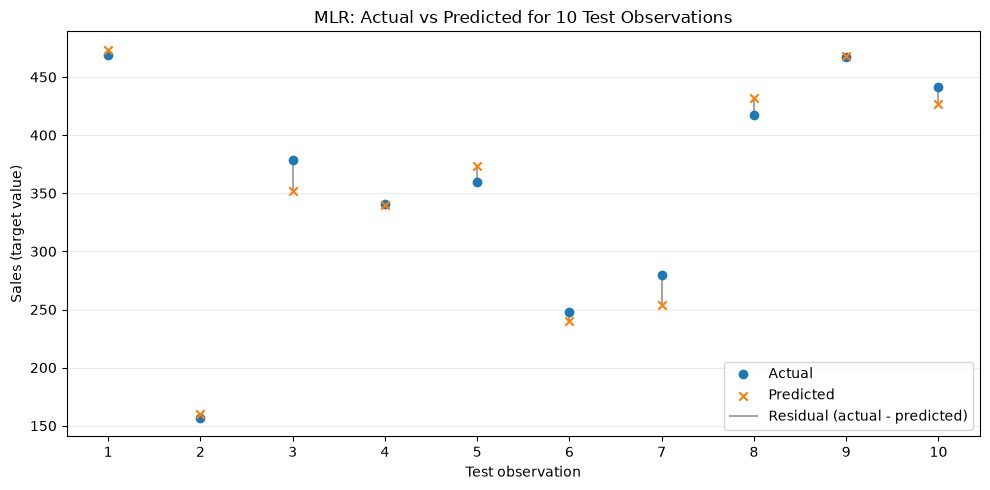

In [6]:
n_plot = 10
observation_numbers = np.arange(1, n_plot + 1)
actual_values = y_test.iloc[:n_plot].to_numpy()


def plot_predictions(model_name, predicted_values):
    predicted = predicted_values[:n_plot]
    residuals = actual_values - predicted

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.scatter(observation_numbers, actual_values, color="tab:blue", label="Actual", zorder=3)
    ax.scatter(observation_numbers, predicted, color="tab:orange", marker="x", label="Predicted", zorder=3)

    for index, (actual, prediction) in enumerate(zip(actual_values, predicted), start=1):
        ax.plot(
            [index, index],
            [prediction, actual],
            color="gray",
            alpha=0.7,
            label="Residual (actual - predicted)" if index == 1 else None,
        )

    ax.set_title(f"{model_name}: Actual vs Predicted for 10 Test Observations")
    ax.set_xlabel("Test observation")
    ax.set_ylabel("Sales (target value)")
    ax.set_xticks(observation_numbers)
    ax.legend()
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

    return residuals


slr_plot_residuals = plot_predictions("SLR", slr_predictions)
mlr_plot_residuals = plot_predictions("MLR", mlr_predictions)

## 7. Interpret the plots and residuals

A **positive residual** (`actual - predicted > 0`) means the model predicted too low; a **negative residual** means it predicted too high. A residual close to zero indicates a close prediction. The length of each connecting line shows the absolute residual size: longer lines indicate larger prediction errors. Residuals are useful for inspecting individual examples, while the metrics above summarize performance across the full test set.

Because the target was generated using all three features, MLR can use information that SLR omits. Its test metrics will show whether those additional features improve predictions on this dataset.